# Employee Attrition Prediction — Notebook 1: EDA & Data Preparation

This project follows the ML process from the assignment in two notebooks:

| Notebook | Steps covered |
|---|---|
| **01_eda.ipynb** (this one) | 1. Problem Definition · 2. Data Collection · 3. EDA and Data Cleaning |
| **02_model.ipynb** | 3. Feature Engineering, Splitting, Encoding/Scaling · 4. Algorithm Selection · 5. Training · 6. Evaluation & Tuning · 8. Testing & Deployment · 10. Monitoring |

Run this notebook first: it saves the cleaned data that `02_model.ipynb` reads.

## 1. Problem Definition

**Business problem.** Losing an employee is expensive: recruiting, onboarding and lost productivity cost a large share of a year's salary. HR can often keep a person with a stay interview, a pay review or a workload change — but only if it knows *who* is at risk early enough.

**Goal.** Build a model that estimates, for each current employee, the probability that they will leave, so HR can review the highest-risk people first.

| Item | Value |
|---|---|
| ML task | Supervised learning — **binary classification** |
| Target variable | `Attrition` (Yes = left → 1, No = stayed → 0) |
| Class balance | 16.1% left, 83.9% stayed (imbalanced — see Section 3.1) |
| Output | Probability of leaving + a High / Low risk flag |

**Success criteria** (set before modelling, measured on the untouched test set):

| Metric | Target | Why |
|---|---|---|
| ROC-AUC | **≥ 0.80** | the model must rank leavers above stayers well, independent of the threshold |
| Recall (leavers) | **≥ 0.70** | missing a leaver is the costly mistake, so we must catch most of them |
| F1 (leavers) | **≥ 0.50** | flags must stay useful: a random guess at a 16% base rate gives F1 ≈ 0.24 |

Accuracy is reported but is **not** a success criterion: a model that predicts "stays" for everybody is already 84% accurate and useless.

## 2. Data Collection

| Item | Detail |
|---|---|
| Source | Kaggle — *IBM HR Analytics Employee Attrition & Performance* (public dataset) |
| Link | https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset |
| File | `data_ibm/WA_Fn-UseC_-HR-Employee-Attrition.csv` |
| Size | 1,470 employees × 35 columns |
| Content | demographics, job role and level, pay, tenure, overtime, travel, satisfaction surveys (1–4 scales) and the target `Attrition` |

**Does the data represent the problem?** Yes: it contains the information an HR department holds about its staff (role, pay, tenure, workload, survey answers) plus the known outcome. It was created by IBM data scientists to mirror real HR records, so it is fictional but realistic.

**Why this dataset.** The project first used a 10,000-row synthetic Kaggle dataset. Every model on it scored ROC-AUC ≈ 0.50 (the same as shuffled labels) because its columns had no relationship with attrition. A model cannot learn from data like that, so we switched to the IBM dataset, where the EDA below shows clear patterns.

In [1]:
# ==========================================================
# SETUP: libraries, paths, plot style
# ==========================================================
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)

# Works whether the notebook is started from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data_ibm").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data_ibm" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
CLEAN_PATH = ROOT / "data_ibm" / "attrition_clean.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current figure for the report and slides, then show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

TARGET = "Attrition"

## 3. Data Exploration and Preparation

### 3.1 Exploratory Data Analysis (EDA)

#### Load the data

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

1,470 rows x 35 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# ==========================================================
# 3.1 DATA QUALITY CHECK
# ==========================================================
df.info()

n_missing = int(df.isna().sum().sum())
n_dup = int(df.duplicated().sum())
constant_cols = df.columns[df.nunique() == 1].tolist()
id_cols = df.columns[df.nunique() == len(df)].tolist()

print(f"\nMissing values : {n_missing}")
print(f"Duplicate rows : {n_dup}")
print(f"Constant cols  : {constant_cols}")
print(f"ID-like cols   : {id_cols}")

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


**Data quality findings**

- **Structure:** 1,470 rows, 35 columns — 26 numeric and 9 text columns (including the target).
- **Missing values: 0. Duplicate rows: 0.** No imputation or de-duplication is needed.
- **Constant columns:** `EmployeeCount` (always 1), `Over18` (always "Y") and `StandardHours` (always 80) are the same for everyone, so they carry no information.
- **ID column:** `EmployeeNumber` is unique per row — an identifier, not a predictor.
- **Scales:** satisfaction, involvement and work-life balance are 1–4 ratings; `Education` and `JobLevel` are 1–5; `StockOptionLevel` is 0–3. Money and year columns are on much larger scales, so scaling is needed before Logistic Regression.

Attrition
No     1233
Yes     237

Attrition rate: 16.1%


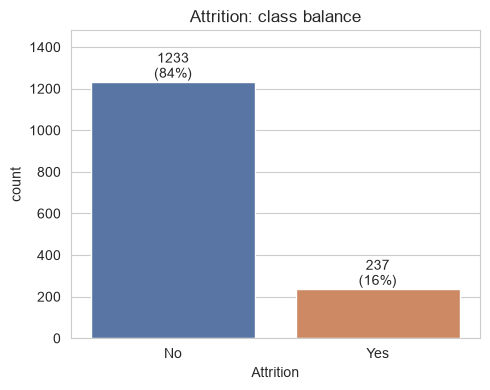

In [5]:
# ==========================================================
# 3.1 TARGET VARIABLE
# ==========================================================
df["Attrition_flag"] = df[TARGET].map({"Yes": 1, "No": 0})
counts = df[TARGET].value_counts()
print(counts.to_string())
print(f"\nAttrition rate: {df['Attrition_flag'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, order=["No", "Yes"], hue=TARGET, hue_order=["No", "Yes"],
              palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}\n({p.get_height()/len(df):.0%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Attrition: class balance")
ax.set_ylim(0, counts.max() * 1.2)
save_fig("01_target_balance")

**Target balance:** 237 of 1,470 employees left (**16.1%**). The classes are imbalanced (about 1 leaver for every 5 stayers). Consequences for modelling:
- splits must be **stratified** so every set keeps the 16% rate;
- models use **class weights** so the minority class is not ignored;
- we judge models with **ROC-AUC, recall and F1**, not accuracy.

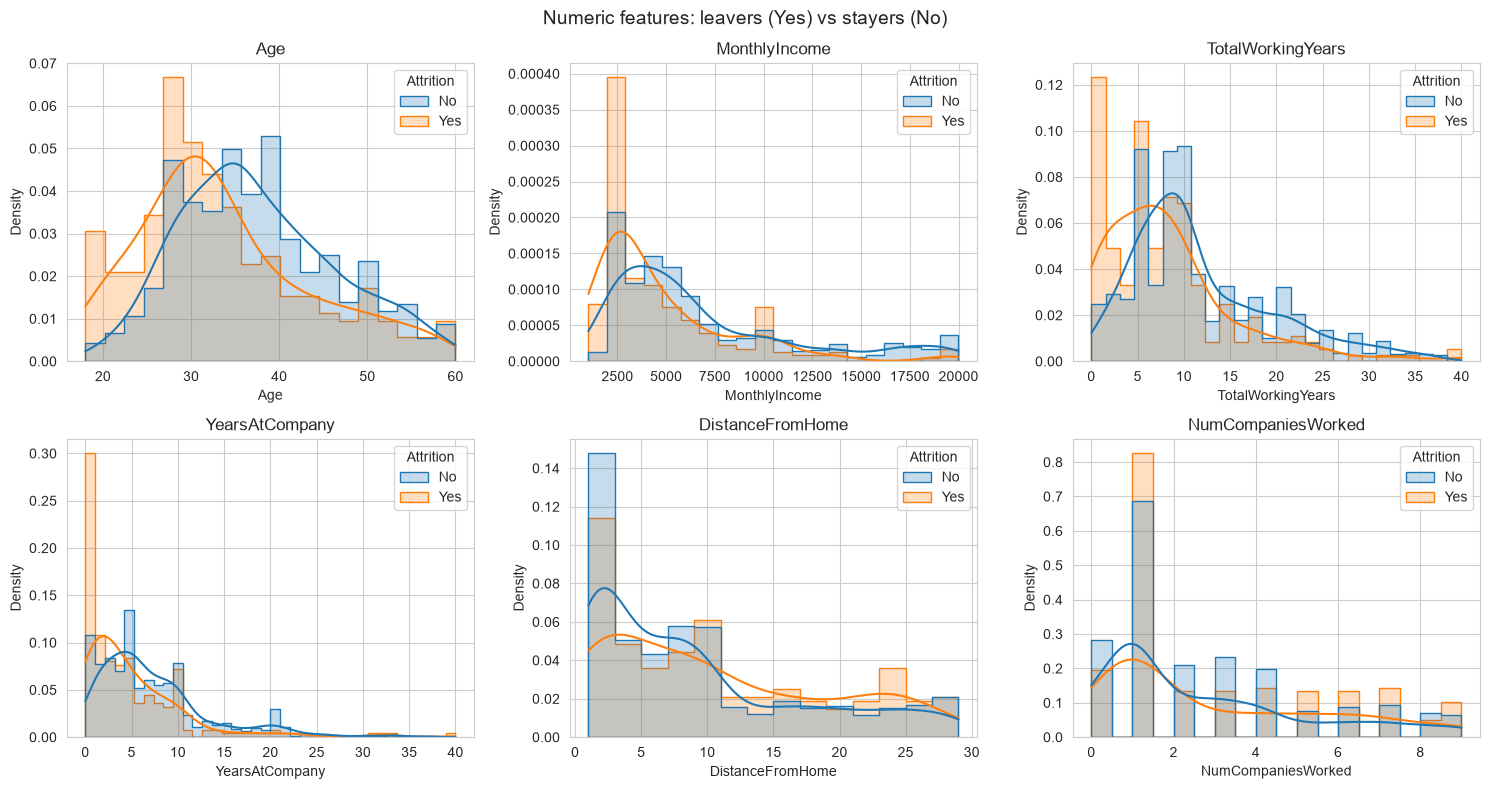

Median values by attrition:


Attrition,No,Yes
Age,36.0,32.0
MonthlyIncome,5204.0,3202.0
TotalWorkingYears,10.0,7.0
YearsAtCompany,6.0,3.0
DistanceFromHome,7.0,9.0
NumCompaniesWorked,2.0,1.0


In [6]:
# ==========================================================
# 3.1 NUMERIC FEATURES: distribution by attrition
# ==========================================================
key_numeric = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
               "DistanceFromHome", "NumCompaniesWorked"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.histplot(data=df, x=col, hue=TARGET, stat="density", common_norm=False,
                 kde=True, element="step", ax=ax, hue_order=["No", "Yes"])
    ax.set_title(col)
fig.suptitle("Numeric features: leavers (Yes) vs stayers (No)", fontsize=14)
save_fig("02_numeric_distributions")

print("Median values by attrition:")
df.groupby(TARGET)[key_numeric].median().T

**Numeric distributions.** Leavers are clearly different from stayers:
- **younger** (median age 32 vs 36) and **earlier in their career** (7 vs 10 total working years);
- **paid less** (median monthly income $3,202 vs $5,204);
- **newer to the company** (median 3 vs 6 years);
- live slightly **further from work** (median 9 vs 7 km).

Income, total working years and years at the company are right-skewed (a long tail of senior, long-serving staff).

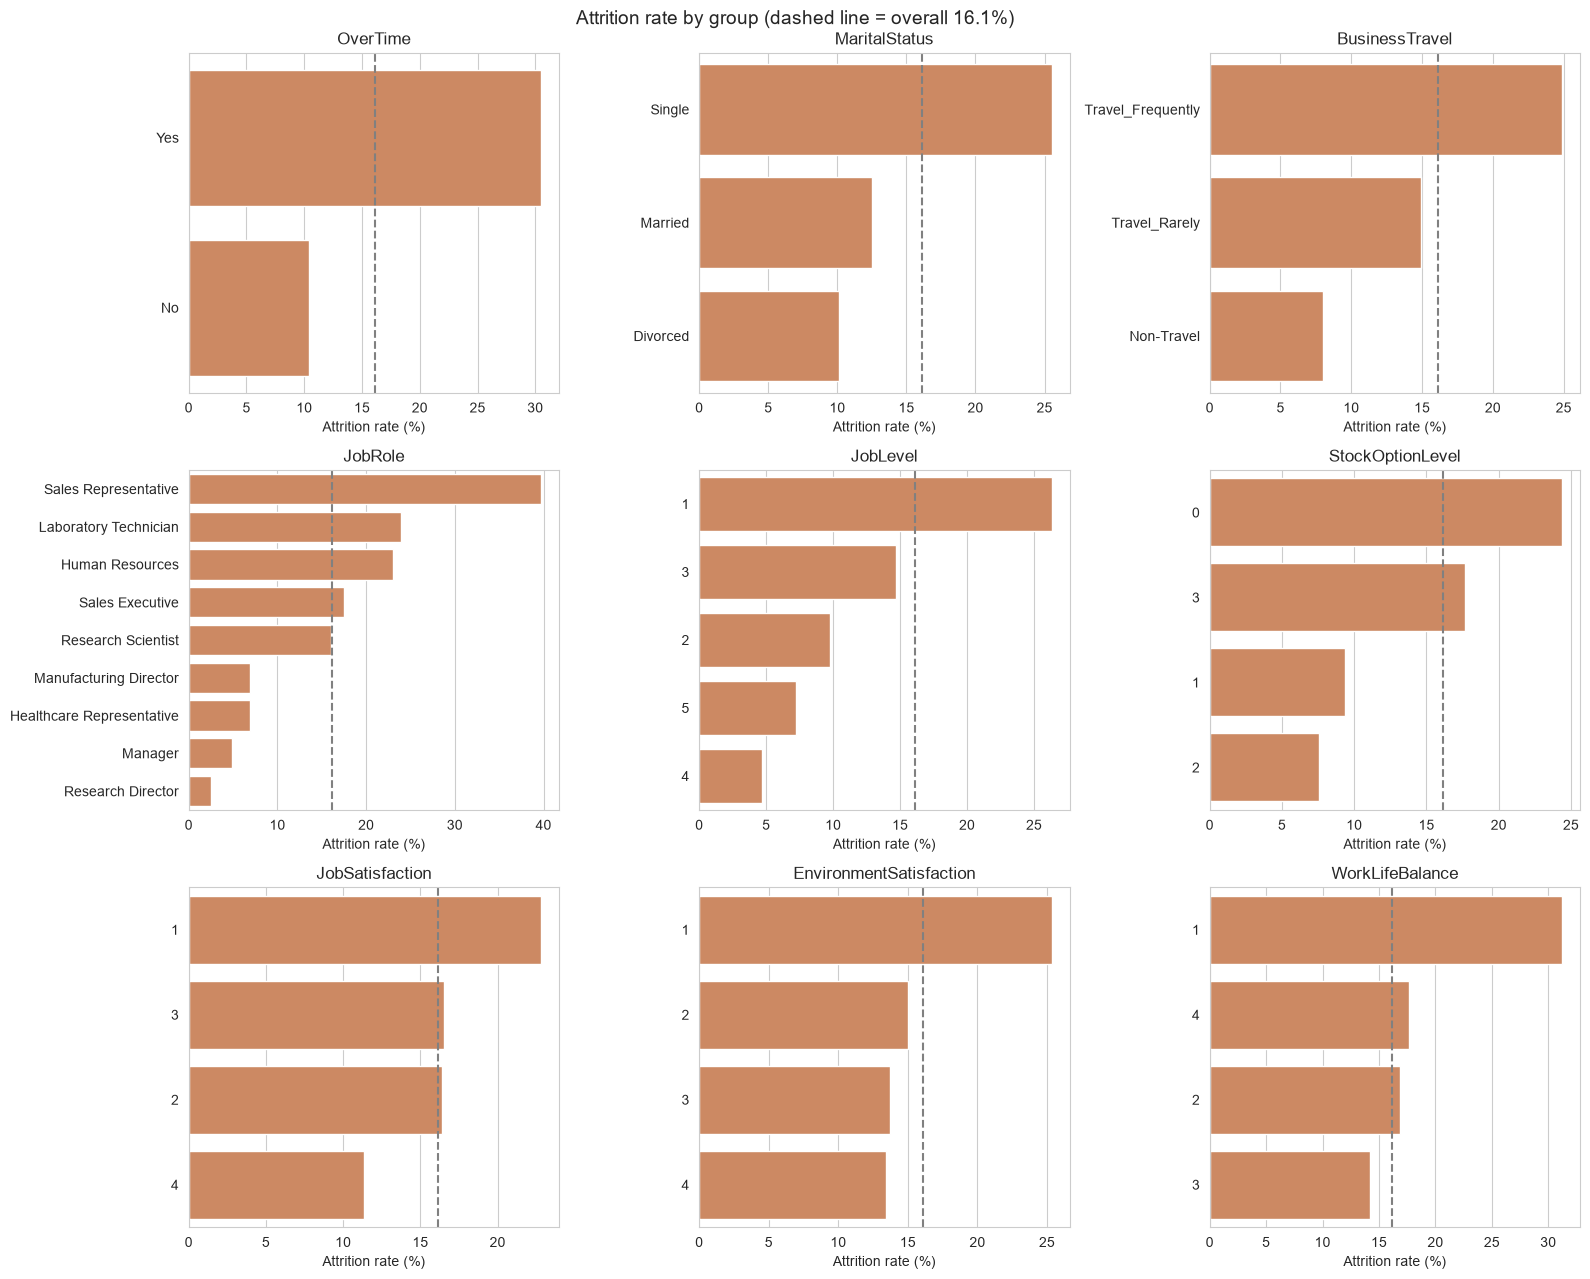

OverTime {'No': 10.4, 'Yes': 30.5}
MaritalStatus {'Divorced': 10.1, 'Married': 12.5, 'Single': 25.5}
BusinessTravel {'Non-Travel': 8.0, 'Travel_Frequently': 24.9, 'Travel_Rarely': 15.0}
JobRole {'Healthcare Representative': 6.9, 'Human Resources': 23.1, 'Laboratory Technician': 23.9, 'Manager': 4.9, 'Manufacturing Director': 6.9, 'Research Director': 2.5, 'Research Scientist': 16.1, 'Sales Executive': 17.5, 'Sales Representative': 39.8}
JobLevel {1: 26.3, 2: 9.7, 3: 14.7, 4: 4.7, 5: 7.2}
StockOptionLevel {0: 24.4, 1: 9.4, 2: 7.6, 3: 17.6}
JobSatisfaction {1: 22.8, 2: 16.4, 3: 16.5, 4: 11.3}
EnvironmentSatisfaction {1: 25.4, 2: 15.0, 3: 13.7, 4: 13.5}
WorkLifeBalance {1: 31.2, 2: 16.9, 3: 14.2, 4: 17.6}


In [7]:
# ==========================================================
# 3.1 CATEGORICAL / RATING FEATURES: attrition rate per group
# ==========================================================
group_cols = ["OverTime", "MaritalStatus", "BusinessTravel", "JobRole",
              "JobLevel", "StockOptionLevel", "JobSatisfaction", "EnvironmentSatisfaction",
              "WorkLifeBalance"]
overall = df["Attrition_flag"].mean() * 100

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.ravel(), group_cols):
    rate = df.groupby(col)["Attrition_flag"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index.astype(str), color="#DD8452", ax=ax)
    ax.axvline(overall, ls="--", c="grey")
    ax.set_title(f"{col}")
    ax.set_xlabel("Attrition rate (%)")
    ax.set_ylabel("")
fig.suptitle(f"Attrition rate by group (dashed line = overall {overall:.1f}%)", fontsize=14)
save_fig("03_attrition_rate_by_group")

for col in group_cols:
    print(col, df.groupby(col)["Attrition_flag"].mean().mul(100).round(1).to_dict())

**Attrition rate by group** (overall rate 16.1%):

| Factor | Highest risk | Lowest risk |
|---|---|---|
| **OverTime** | Yes: **30.5%** | No: 10.4% |
| **Job role** | Sales Representative: **39.8%**, Lab Technician 23.9%, HR 23.1% | Research Director 2.5%, Manager 4.9% |
| **Marital status** | Single: **25.5%** | Divorced: 10.1% |
| **Business travel** | Travel frequently: **24.9%** | Non-travel: 8.0% |
| **Job level** | Level 1 (entry): **26.3%** | Level 4: 4.7% |
| **Stock options** | Level 0 (none): **24.4%** | Level 2: 7.6% |
| **Surveys** | the lowest score (1) has the highest rate in every survey, e.g. work-life balance 1: **31.2%**, job involvement 1: **33.7%** | |

Overtime, junior roles, being single, frequent travel and no stock options are the strongest warning signs. Low survey scores matter too, mostly in the lowest category.

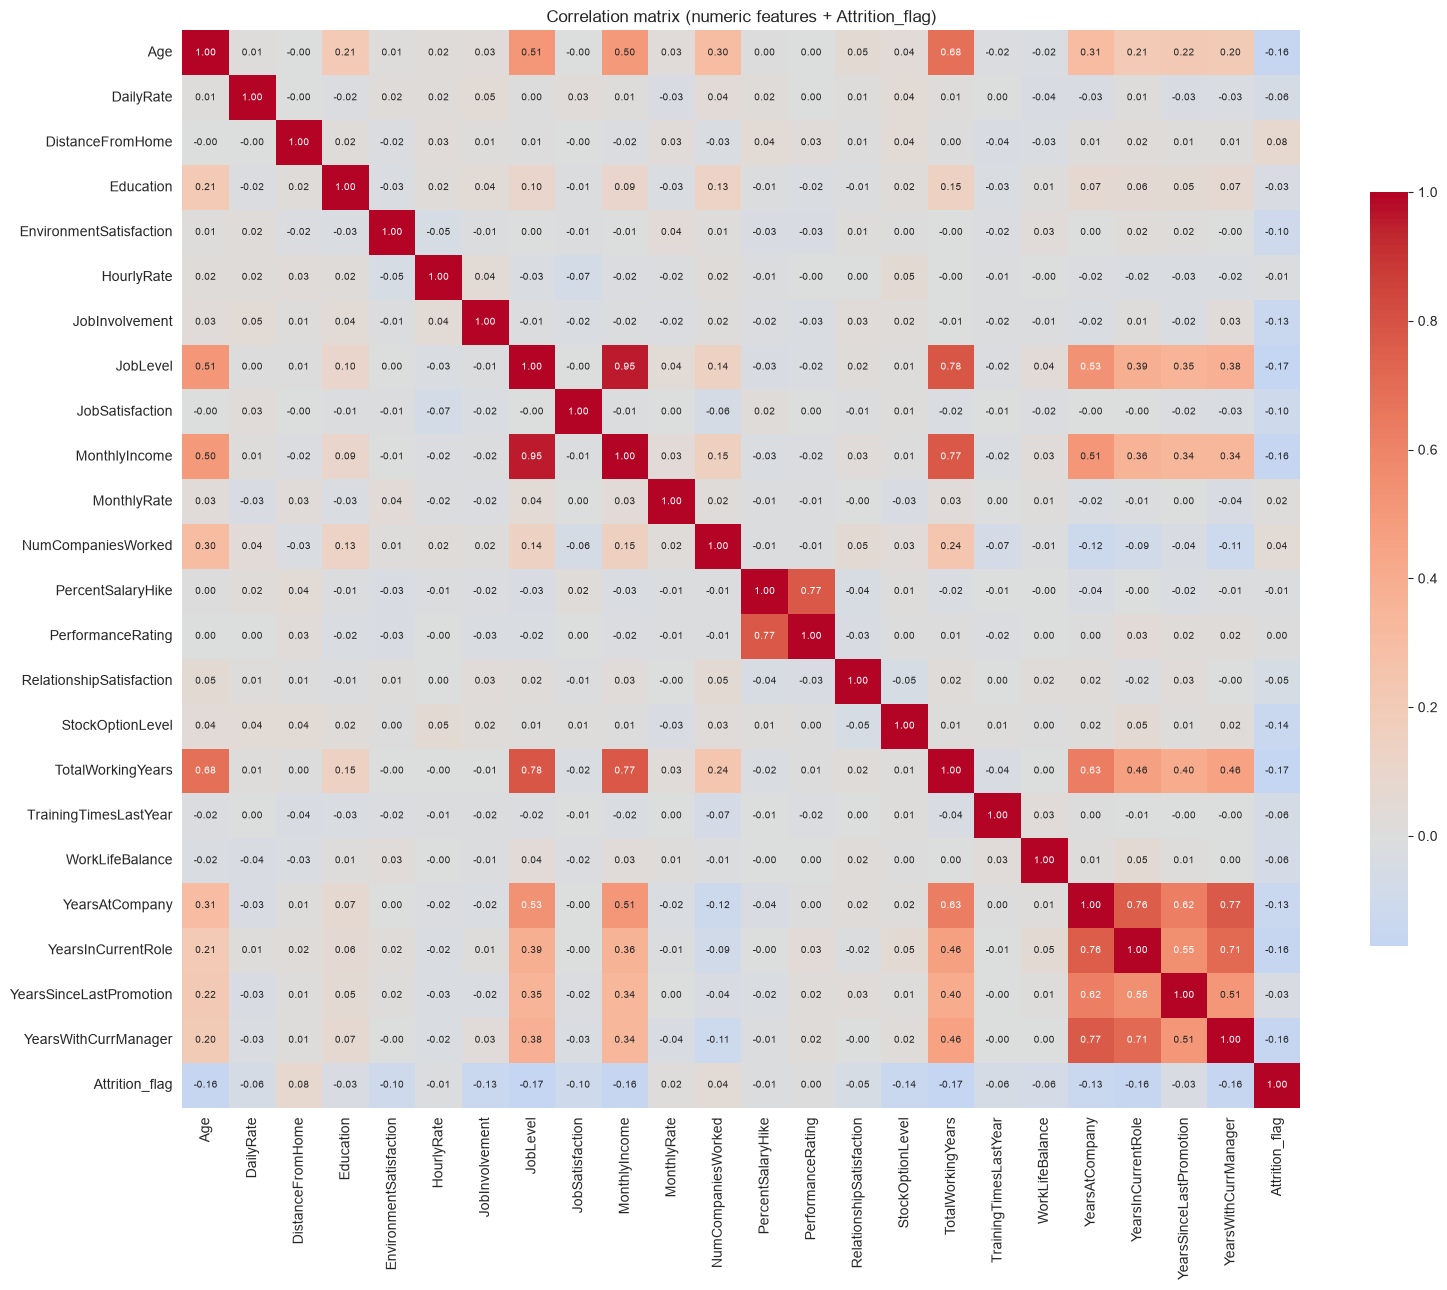

Strongest correlations with attrition:
TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
JobInvolvement         -0.130
JobSatisfaction        -0.103

Highly correlated feature pairs (|r| > 0.7):
JobLevel            MonthlyIncome           0.950
                    TotalWorkingYears       0.782
PercentSalaryHike   PerformanceRating       0.774
MonthlyIncome       TotalWorkingYears       0.773
YearsAtCompany      YearsWithCurrManager    0.769
                    YearsInCurrentRole      0.759
YearsInCurrentRole  YearsWithCurrManager    0.714

Do the 'rate' columns behave like pay? Correlation with MonthlyIncome:
DailyRate      0.008
HourlyRate    -0.016
MonthlyRate    0.035


In [8]:
# ==========================================================
# 3.1 RELATIONSHIPS: correlation heatmap
# ==========================================================
num_df = df.select_dtypes("number").drop(columns=["EmployeeCount", "StandardHours", "EmployeeNumber"])
corr = num_df.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.7})
plt.title("Correlation matrix (numeric features + Attrition_flag)")
save_fig("04_correlation_heatmap")

print("Strongest correlations with attrition:")
target_corr = corr["Attrition_flag"].drop("Attrition_flag")
print(target_corr.reindex(target_corr.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("\nHighly correlated feature pairs (|r| > 0.7):")
print(pairs[pairs.abs() > 0.7].sort_values(ascending=False).round(3).to_string())

print("\nDo the 'rate' columns behave like pay? Correlation with MonthlyIncome:")
print(corr.loc[["DailyRate", "HourlyRate", "MonthlyRate"], "MonthlyIncome"].round(3).to_string())

**Correlations**
- No single numeric feature is strongly correlated with attrition (largest |r| = 0.17). Attrition depends on **several moderate factors together**, which is why a multivariate model is needed.
- The strongest signals all point to **seniority and stability**: more working years, a higher job level, higher income, more age and longer tenure all go with *lower* attrition.
- **Multicollinearity:** `JobLevel` and `MonthlyIncome` carry almost the same information (r = 0.95), and the tenure columns (`YearsAtCompany`, `YearsInCurrentRole`, `YearsWithCurrManager`) are strongly related (r ≈ 0.71–0.77). This can make Logistic Regression coefficients unstable, so we use regularisation; tree models are not affected.
- **`DailyRate`, `HourlyRate`, `MonthlyRate`** are undocumented columns that, despite their names, have essentially **no correlation with `MonthlyIncome`** (|r| ≤ 0.04). They do not behave like pay and their meaning is unknown, so they are dropped in cleaning.

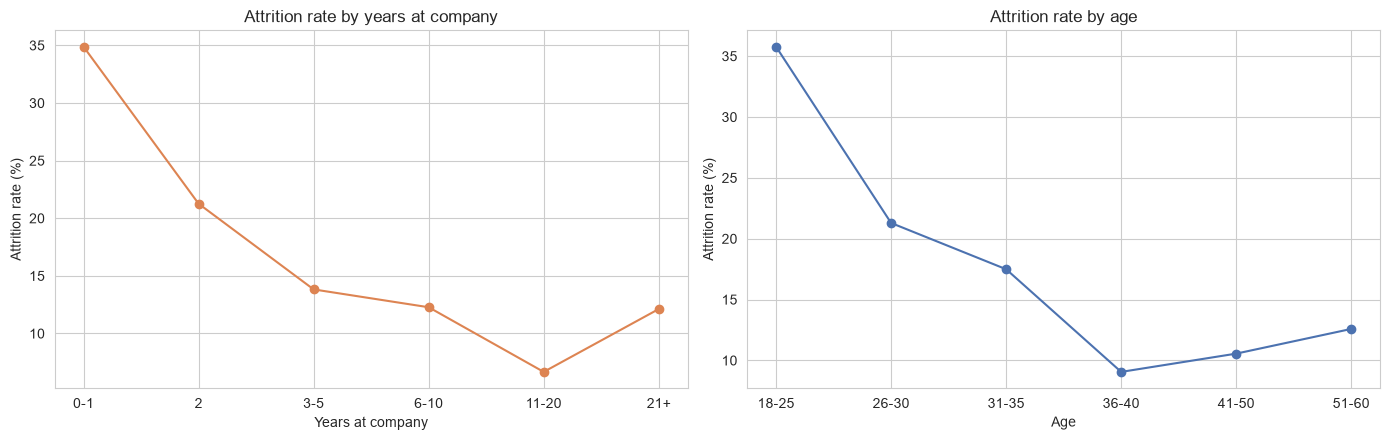

0-1      34.9
2        21.3
3-5      13.8
6-10     12.3
11-20     6.7
21+      12.1
18-25    35.8
26-30    21.3
31-35    17.5
36-40     9.1
41-50    10.6
51-60    12.6


In [9]:
# ==========================================================
# 3.1 TREND: attrition by tenure and age
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tenure = df.groupby(pd.cut(df["YearsAtCompany"], [-1, 1, 2, 5, 10, 20, 40]))["Attrition_flag"].mean() * 100
tenure.index = ["0-1", "2", "3-5", "6-10", "11-20", "21+"]
tenure.plot(marker="o", ax=axes[0], color="#DD8452")
axes[0].set_title("Attrition rate by years at company")
axes[0].set_ylabel("Attrition rate (%)")
axes[0].set_xlabel("Years at company")

age = df.groupby(pd.cut(df["Age"], [17, 25, 30, 35, 40, 50, 60]))["Attrition_flag"].mean() * 100
age.index = ["18-25", "26-30", "31-35", "36-40", "41-50", "51-60"]
age.plot(marker="o", ax=axes[1], color="#4C72B0")
axes[1].set_title("Attrition rate by age")
axes[1].set_ylabel("Attrition rate (%)")
axes[1].set_xlabel("Age")
save_fig("05_trends_tenure_age")
print(tenure.round(1).to_string())
print(age.round(1).to_string())

**Trends:** risk is highest at the very start — **34.9%** of employees with 0–1 years at the company leave, falling to about 7% at 11–20 years. By age, **35.8%** of 18–25-year-olds leave versus about 9–13% after 35. Retention efforts should focus on new joiners and young employees.

,Feature,Outliers,Min,Max,Skew
4,MonthlyIncome,114,1009,19999,1.37
10,YearsSinceLastPromotion,107,0,15,1.98
8,YearsAtCompany,104,0,40,1.76
7,TotalWorkingYears,63,0,40,1.12
9,YearsInCurrentRole,21,0,18,0.92
11,YearsWithCurrManager,14,0,17,0.83
1,DailyRate,0,102,1499,-0.00
0,Age,0,18,60,0.41
3,HourlyRate,0,30,100,-0.03
2,DistanceFromHome,0,1,29,0.96


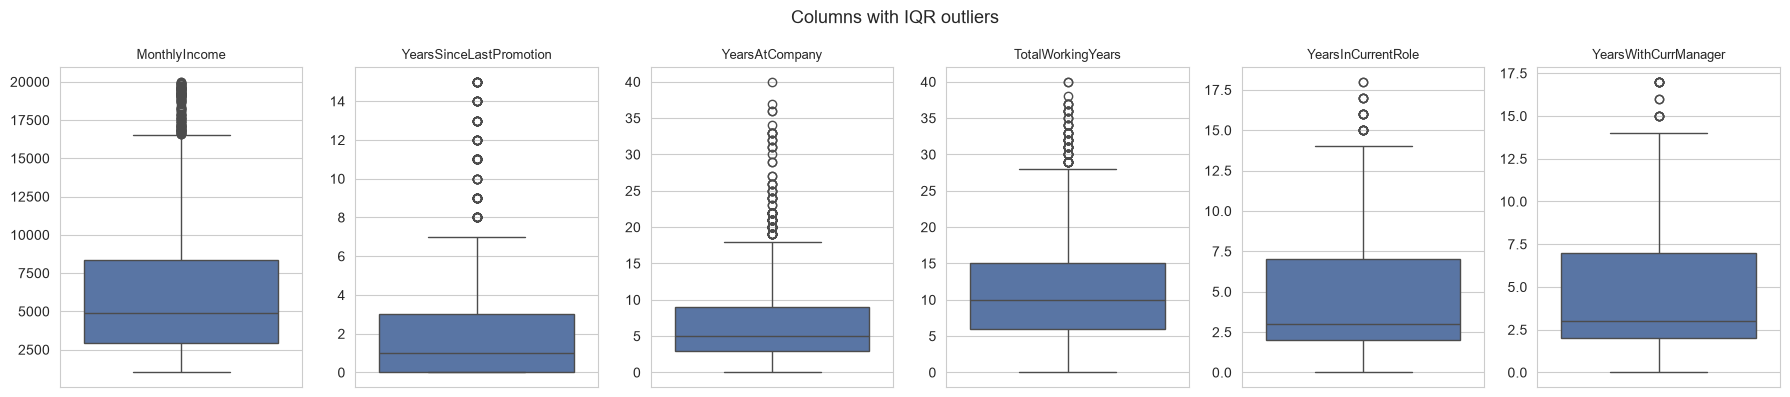

Job level of employees with an outlying MonthlyIncome:
JobLevel
4    45
5    69


In [10]:
# ==========================================================
# 3.1 OUTLIERS (IQR rule on continuous columns)
# ==========================================================
cont_cols = [c for c in num_df.columns if num_df[c].nunique() > 10 and c != "Attrition_flag"]
rows = []
for c in cont_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    rows.append((c, int(((df[c] < lo) | (df[c] > hi)).sum()), df[c].min(), df[c].max(), round(df[c].skew(), 2)))
outliers = pd.DataFrame(rows, columns=["Feature", "Outliers", "Min", "Max", "Skew"]).sort_values("Outliers", ascending=False)
display(outliers)

out_cols = outliers.query("Outliers > 0")["Feature"].tolist()
fig, axes = plt.subplots(1, len(out_cols), figsize=(3 * len(out_cols), 4))
for ax, c in zip(np.atleast_1d(axes), out_cols):
    sns.boxplot(y=df[c], ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=9)
    ax.set_ylabel("")
fig.suptitle("Columns with IQR outliers", fontsize=13)
save_fig("06_outliers_boxplots")

# Are the outliers real? High earners should be senior (high job level).
print("Job level of employees with an outlying MonthlyIncome:")
q1, q3 = df["MonthlyIncome"].quantile([0.25, 0.75])
print(df.loc[df["MonthlyIncome"] > q3 + 1.5 * (q3 - q1), "JobLevel"].value_counts().sort_index().to_string())

**Outliers:** the IQR rule flags values in six columns, mostly `MonthlyIncome` (114), `YearsSinceLastPromotion` (107) and `YearsAtCompany` (104). They are **genuine, not errors**: every employee with an outlying income is at job level 4 or 5 (senior staff), and long tenures or long gaps since promotion are realistic. Removing them would delete the senior employees the model must also score, so **we keep them**. Numeric columns are standardised later, and the tree-based models are not sensitive to extreme values.

In [11]:
# ==========================================================
# 3.1 LOGICAL CONSISTENCY (timelines must make sense)
# ==========================================================
rules = {
    "YearsAtCompany > TotalWorkingYears": df["YearsAtCompany"] > df["TotalWorkingYears"],
    "YearsInCurrentRole > YearsAtCompany": df["YearsInCurrentRole"] > df["YearsAtCompany"],
    "YearsSinceLastPromotion > YearsAtCompany": df["YearsSinceLastPromotion"] > df["YearsAtCompany"],
    "YearsWithCurrManager > YearsAtCompany": df["YearsWithCurrManager"] > df["YearsAtCompany"],
    "TotalWorkingYears > Age - 16": df["TotalWorkingYears"] > df["Age"] - 16,
}
for name, mask in rules.items():
    print(f"{name:42s}: {int(mask.sum())} rows")

YearsAtCompany > TotalWorkingYears        : 0 rows
YearsInCurrentRole > YearsAtCompany       : 0 rows
YearsSinceLastPromotion > YearsAtCompany  : 0 rows
YearsWithCurrManager > YearsAtCompany     : 0 rows
TotalWorkingYears > Age - 16              : 0 rows


**Logical consistency:** all 1,470 rows pass every timeline rule (no one has more years at the company than in their whole career, more years in role than at the company, and so on). No fixes needed.

### 3.2 Data Cleaning

The checks above decide what cleaning is needed:

| Problem | Found | Action |
|---|---|---|
| Missing values | 0 | none needed (the code still drops rows with a missing target) |
| Duplicate rows | 0 | none needed (the code still removes them) |
| Inconsistent timelines | 0 | none needed (the code still removes rule-breaking rows) |
| Outliers | 6 columns | **kept** — genuine senior / long-tenure employees |
| Constant columns | 3 | **dropped**: `EmployeeCount`, `Over18`, `StandardHours` |
| ID column | 1 | **dropped**: `EmployeeNumber` |
| Meaningless rate columns | 3 | **dropped**: `DailyRate`, `HourlyRate`, `MonthlyRate` |

In [12]:
# ==========================================================
# 3.2 DATA CLEANING: fix what the checks found, then verify
# ==========================================================
data = df.drop(columns=["Attrition_flag"]).copy()
n_rows, n_cols = data.shape

# 1. Missing values and duplicates (none found, but handled so the code is reusable)
data = data.dropna(subset=[TARGET])
data = data.drop_duplicates()

# 2. Inconsistent timelines (none found): drop any row that breaks a rule
bad = pd.concat([m.reindex(data.index, fill_value=False) for m in rules.values()], axis=1).any(axis=1)
data = data[~bad]

# 3. Columns with no useful information
drop_cols = {
    "EmployeeCount": "constant (always 1)",
    "Over18": "constant (always 'Y')",
    "StandardHours": "constant (always 80)",
    "EmployeeNumber": "row ID, no meaning",
    "DailyRate": "undocumented rate, ~0 correlation with MonthlyIncome",
    "HourlyRate": "undocumented rate, ~0 correlation with MonthlyIncome",
    "MonthlyRate": "undocumented rate, ~0 correlation with MonthlyIncome",
}
data = data.drop(columns=list(drop_cols))

# 4. Outliers: kept on purpose (they are real senior / long-serving employees)

print("Dropped columns:")
for c, why in drop_cols.items():
    print(f"  {c:15s} {why}")
print(f"\nRows   : {n_rows} -> {len(data)}")
print(f"Columns: {n_cols} -> {data.shape[1]}")
print(f"Missing values left: {int(data.isna().sum().sum())} | Duplicates left: {int(data.duplicated().sum())}")

Dropped columns:
  EmployeeCount   constant (always 1)
  Over18          constant (always 'Y')
  StandardHours   constant (always 80)
  EmployeeNumber  row ID, no meaning
  DailyRate       undocumented rate, ~0 correlation with MonthlyIncome
  HourlyRate      undocumented rate, ~0 correlation with MonthlyIncome
  MonthlyRate     undocumented rate, ~0 correlation with MonthlyIncome

Rows   : 1470 -> 1470
Columns: 35 -> 28
Missing values left: 0 | Duplicates left: 0


In [13]:
data.to_csv(CLEAN_PATH, index=False)
print(f"Cleaned data saved to {CLEAN_PATH.relative_to(ROOT)}  ({data.shape[0]} rows x {data.shape[1]} columns)")

Cleaned data saved to data_ibm\attrition_clean.csv  (1470 rows x 28 columns)


### Summary of Notebook 1

- The IBM data is complete and consistent: no missing values, duplicates or impossible timelines.
- 7 columns with no useful information were dropped and all 1,470 rows were kept. The cleaned file `data_ibm/attrition_clean.csv` has **1,470 rows × 28 columns** (27 inputs + target).
- 16.1% of employees left; the classes are imbalanced.
- The main drivers of attrition are **overtime, junior level / low pay, short tenure, young age, being single, frequent travel, no stock options and low satisfaction scores**.

**Next:** `02_model.ipynb` — feature engineering, splitting, training, tuning, testing and deployment.